<a href="https://colab.research.google.com/github/NohailaAitHammad/plandaction/blob/main/plan_action_NohailaAitHammad.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

**Exploration et analyse des données (EDA)**


*   Charger le dataset et examiner sa structure : head(), shape(), info() et describe().
* Identifier les variables numériques et catégorielles.
* Analyser les valeurs manquantes, les doublons et les éventuelles incohérences.
* Étudier les distributions des variables à l’aide d’histogrammes et de boxplots.
* Analyser les relations entre les caractéristiques et le prix du diamant.
* Étudier les corrélations entre les variables numériques.
* Détecter les valeurs aberrantes (outliers) à l’aide de la méthode IQR et justifier leur traitement.




In [ ]:
#Chargement de données
df = pd.read_csv('diamonds.csv')

In [ ]:
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [ ]:
df.shape

(50000, 10)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    50000 non-null  float64
 1   cut      50000 non-null  object 
 2   color    50000 non-null  object 
 3   clarity  50000 non-null  object 
 4   depth    50000 non-null  float64
 5   table    50000 non-null  float64
 6   price    50000 non-null  int64  
 7   x        50000 non-null  float64
 8   y        50000 non-null  float64
 9   z        50000 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 3.8+ MB


In [ ]:
numerics_columns = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
categoricals_columns =['cut', 'color', 'clarity']

In [ ]:
df.describe()

,carat,depth,table,price,x,y,z
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,0.799444,61.753006,57.457830,3944.805440,5.734403,5.737956,3.541056
std,0.475173,1.431088,2.232092,3997.938105,1.123077,1.145579,0.707065
min,0.200000,43.000000,43.000000,326.000000,0.000000,0.000000,0.000000
25%,0.400000,61.000000,56.000000,951.000000,4.710000,4.720000,2.910000
50%,0.700000,61.800000,57.000000,2410.000000,5.700000,5.710000,3.530000
75%,1.040000,62.500000,59.000000,5351.000000,6.540000,6.540000,4.040000
max,5.010000,79.000000,95.000000,18823.000000,10.740000,58.900000,31.800000


In [ ]:
df.describe(include=['object'])

,cut,color,clarity
count,50000,50000,50000
unique,5,7,8
top,Ideal,G,SI1
freq,19938,10452,12115


In [ ]:
df.isna().sum()

,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
price,0
x,0
y,0
z,0


In [ ]:
df.duplicated().sum()

np.int64(126)

la variable price contient des valeurs aberantes

<Axes: >

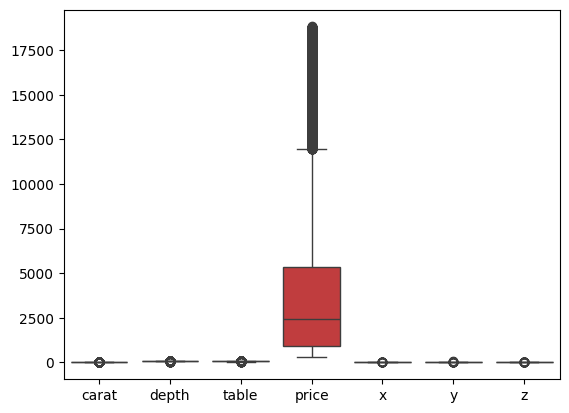

In [ ]:
sns.boxplot(df)

D'apres l'interpretation des histogrames et la mediane et la moyenne nous constatant que la distribution des variables numeriques est normal

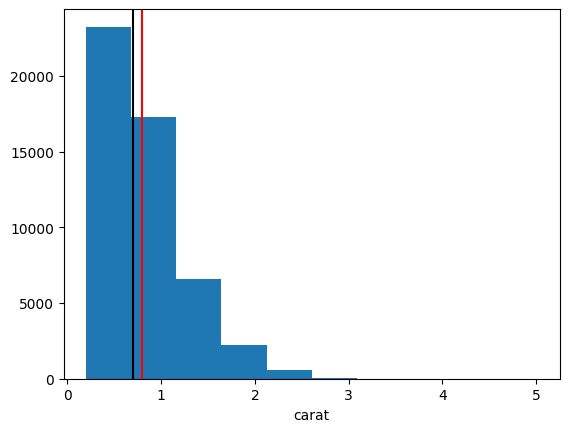

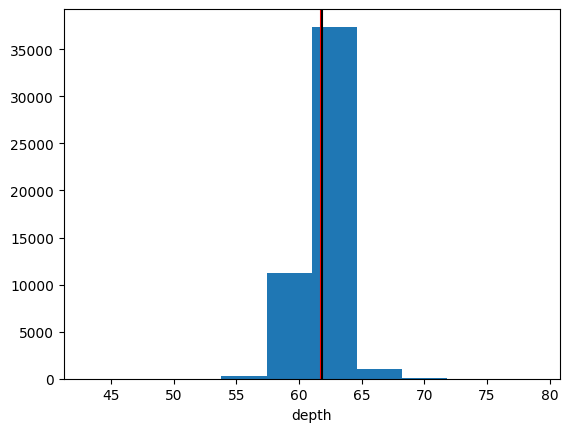

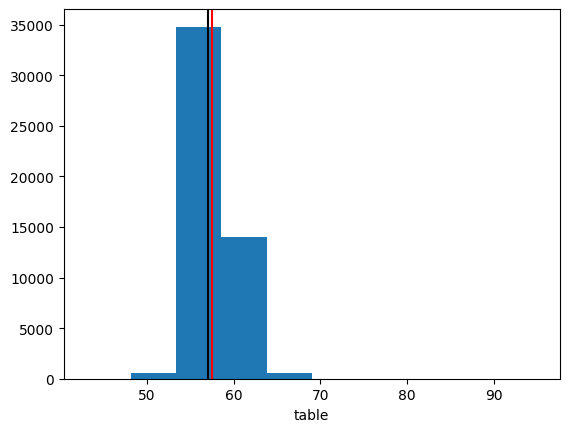

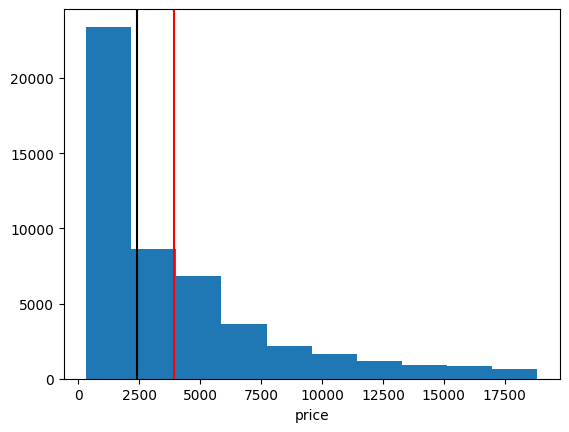

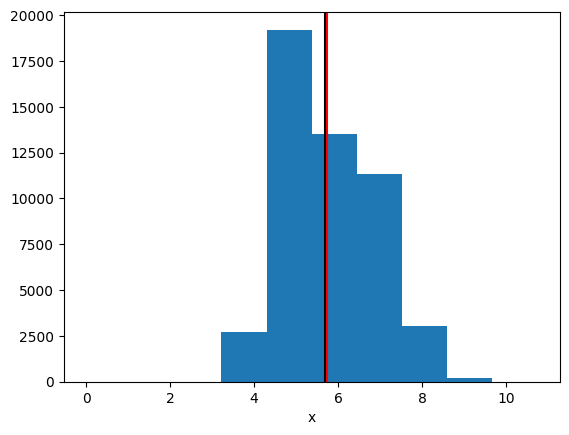

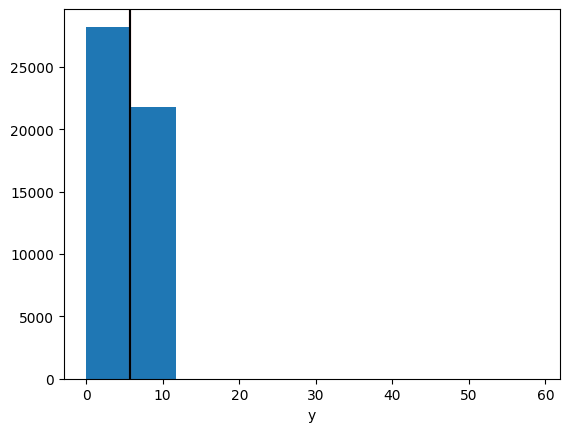

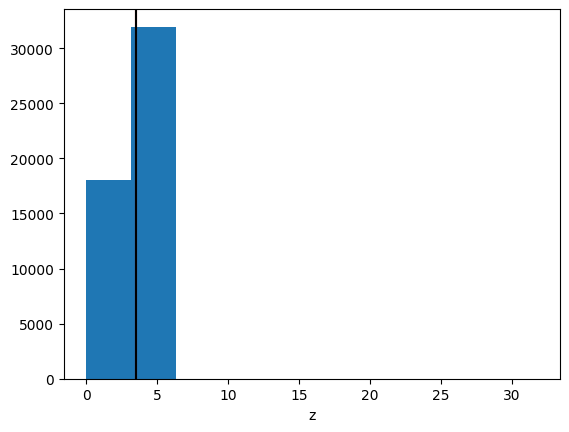

In [ ]:
for col in numerics_columns:
  plt.hist(df[col])
  plt.axvline(df[col].mean(), c='r')
  plt.axvline(df[col].median(), c='black')
  plt.xlabel(col)
  plt.show()

According to the interpretation of the heatmap, we find that there is a strong correlation between price and cart and x et y et z.

<Axes: >

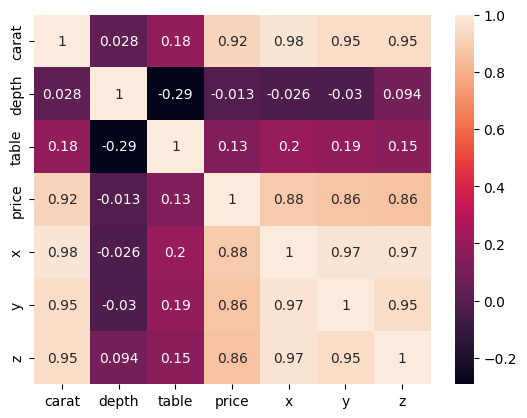

In [ ]:
sns.heatmap(df[numerics_columns].corr(), annot=True)

**2. Nettoyage des données (Data Cleaning)**
* Traiter les valeurs manquantes selon la nature des variables.
* Supprimer les doublons lorsque cela est justifié.
* Corriger les incohérences et les valeurs impossibles.
* Traiter les valeurs aberrantes en justifiant les décisions prises.
* Vérifier la qualité des données après nettoyage.

In [ ]:
df_clean = df.copy()

**Dans la phase de EDA j'ai observé qu'il existe  des doublons , la decision c'est de les supprimer.**



In [ ]:
df_clean.drop_duplicates(inplace=True)

D'apres le boxPlot nous avant constater qu'il ya des outliers, la dicision est d'utiliser le IQR et replacer les valeurs aberants par les bornes inf ou sup (la suppression des outlirs n'etait pas bonnes car meme ils ont ete supprimer il existent autres)

<Axes: >

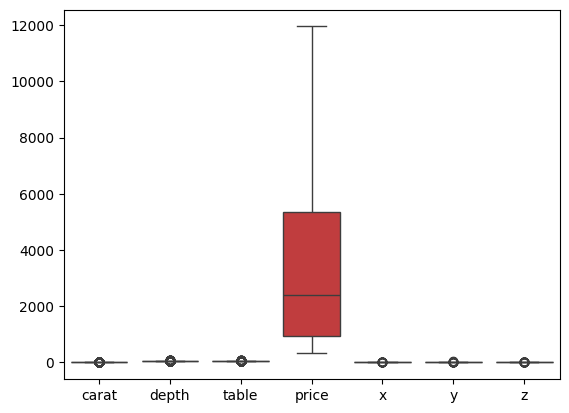

In [ ]:
Q1 = df_clean["price"].quantile(0.25)
Q3 = df_clean["price"].quantile(0.75)
IQR = Q3-Q1
lower_bound = Q1 - 1.5* IQR
upper_bound = Q3 + 1.5* IQR
df_clean['price'] = np.clip(df_clean['price'], lower_bound, upper_bound)
sns.boxplot(df_clean)


**3. Préparation des données**
* Définir la variable cible y correspondant au prix du diamant.
* Définir les variables explicatives X.
* Identifier les variables numériques, nominales et ordinales.
* Écarter les identifiants ou les variables non pertinentes, en justifiant leur exclusion.

In [ ]:
X = df_clean[df_clean.columns.difference(other=['price'])]
y = df_clean['price']

In [ ]:
y.head()

,price
0,326
1,326
2,327
3,334
4,335


In [ ]:
numeric_columns = ['carat', 'depth', 'table', 'x', 'y', 'z']
nominal_columns = ['color', 'clarity']
ordinal_columns = ['cut']

**4. Séparation des données (Train/Test Split)**
* Séparer les données en un ensemble d’entraînement et un ensemble de test, par exemple avec une proportion de 80 % / 20 %.
* Utiliser random_state pour assurer la reproductibilité.
* Réaliser le split avant d’apprendre les paramètres des transformations afin d’éviter toute fuite de données (Data Leakage).

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True)

**5. Prétraitement des données (Preprocessing)**
* Standardiser les variables numériques lorsque cela est pertinent.
* Encoder les variables catégorielles nominales avec OneHotEncoder.
* Utiliser OrdinalEncoder pour les variables ordinales, si nécessaire, en définissant explicitement leur ordre.
* Regrouper les transformations dans un ColumnTransformer.
* Gérer les éventuelles valeurs manquantes à l’aide d’imputeurs adaptés.

In [ ]:
numerics_transform = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler() )
])

In [ ]:
nominal_transform = Pipeline(steps=[
     ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehotencoder', OneHotEncoder())
])

In [ ]:
order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
ordinal_transform = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinalencode', OrdinalEncoder(categories=[order]))
])

In [ ]:

preprocessing = ColumnTransformer(
    transformers=[
    ('numerics', numerics_transform, numeric_columns),
    ('ordinals', ordinal_transform, ordinal_columns),
    ('nominals', nominal_transform, nominal_columns),
], remainder='passthrough')

**6. Construction des pipelines**
* Créer un pipeline complet intégrant le prétraitement et l’algorithme de régression.
* Construire un pipeline distinct pour chaque algorithme.
* Vérifier que les transformations sont apprises uniquement à partir des données d’entraînement de chaque fold.

**7. Entraînement de deux algorithmes de régression**
* Choisir et entraîner les deux algorithmes suivants :
* Algorithme 1 : LinearRegression — modèle de référence permettant d’étudier les relations linéaires entre les caractéristiques et le prix.
* Algorithme 2 : RandomForestRegressor — modèle capable de capturer des relations non linéaires et des interactions entre les variables.

In [ ]:
from sklearn.metrics import r2_score, mean_squared_error, root_mean_squared_error, mean_absolute_error
from sklearn.model_selection import GridSearchCV, cross_val_score

In [ ]:
pipeline1 = Pipeline(steps=[
      ('preprocessor', preprocessing),
      ('regressor', LinearRegression())])

pipeline1.fit(X_train, y_train)
y_pred1 = pipeline1.predict(X_test)
r2_score(y_test, y_pred1)


0.9246255377166048

In [ ]:
pipeline2 = Pipeline(steps=[
      ('preprocessor', preprocessing),
      ('regressor', RandomForestRegressor(random_state=42))])

pipeline2.fit(X_train, y_train)
y_pred2 = pipeline2.predict(X_test)
r2_score(y_test, y_pred2)

0.9871995493723593

**8. Validation croisée (Cross-Validation)**
* Utiliser KFold ou la validation croisée intégrée à GridSearchCV.
* Appliquer une validation croisée à 5 folds, par exemple.
* Comparer les performances moyennes des deux algorithmes sur les mêmes données d’entraînement. Examiner la variabilité des scores entre les folds.

In [ ]:
kf = 5
params = {
    'regressor__fit_intercept' : [True, False],
    'regressor__positive' : [True, False]
}
grid = GridSearchCV(estimator=pipeline1, param_grid=params, cv=kf, scoring='neg_root_mean_squared_error')


In [ ]:
grid.fit(X_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(remainder='passthrough',
                                                          transformers=[('numerics',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='median')),
                                                                                         ('scaler',
                                                                                          StandardScaler())]),
                                                                         ['carat',
                                                                          'depth',
                                                                          'table',
                                                                          'x',
                                                                          'y',
                                                                          'z']),
                                                                        ('ordinals',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('ordinalenc...
                                                                                                                      'Good',
                                                                                                                      'Very '
                                                                                                                      'Good',
                                                                                                                      'Premium',
                                                                                                                      'Ideal']]))]),
                                                                         ['cut']),
                                                                        ('nominals',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehotencoder',
                                                                                          OneHotEncoder())]),
                                                                         ['color',
                                                                          'clarity'])])),
                                       ('regressor', LinearRegression())]),
             param_grid={'regressor__fit_intercept': [True, False],
                         'regressor__positive': [True, False]},
             scoring='neg_root_mean_squared_error')

In [ ]:
y_pred_gscv1  =  grid.predict(X_test)

In [ ]:
r2_score(y_test, y_pred_gscv1)

0.924490117861741

In [ ]:
grid.best_score_

np.float64(-930.5006753863074)

In [ ]:
grid.best_params_

{'regressor__fit_intercept': True, 'regressor__positive': True}

In [ ]:
kf = 5
params = {
    'regressor__n_estimators' : [ 100, 200],
    'regressor__max_depth' : range(1, 10),
    'regressor__min_samples_leaf' : [2, 5, 10]
}
grid1 = GridSearchCV(estimator=pipeline2, param_grid=params, cv=kf, scoring='neg_root_mean_squared_error')
grid1.fit(X_train, y_train)
y_pred_gscv2 = grid1.predict(X_test)
print(grid1.best_params_)
print(grid1.best_score_)

KeyboardInterrupt: 

In [ ]:
r21 = r2_score(y_test, y_pred_gscv1)
r22 = r2_score(y_test, y_pred_gscv2)
r21, r22

In [ ]:
mae1 = mean_absolute_error(y_test, y_pred_gscv1)
mae2 = mean_absolute_error(y_test, y_pred_gscv2)
mae1, mae2

In [ ]:
mse1 = mean_squared_error(y_test, y_pred_gscv1)
mse2 = mean_squared_error(y_test, y_pred_gscv2)
mse1, mse2

In [ ]:
rmse1 = root_mean_squared_error(y_test, y_pred_gscv1)
rmse2 = root_mean_squared_error(y_test, y_pred_gscv2)
rmse1, rmse2

**11. Étude comparative et sélection du meilleur modèle**
* Présenter les résultats des deux modèles dans un tableau comparatif.
* Comparer les scores de validation croisée et les métriques obtenues sur le jeu de test.
* Examiner les écarts entre les performances d’entraînement et de test afin de détecter un éventuel surapprentissage.
* Sélectionner le meilleur modèle en fonction des résultats, de sa capacité de généralisation et de
* l’objectif métier.
* Justifier clairement le choix final.